# IBM Quantum Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 3: Can you change the correlation?

**Goal:** Start from the Bell-state circuit shown in the workshop, add **one** quantum gate, run both circuits for **100 shots**, and compare how the correlation between the two qubits changes.

**Design constraints satisfied:** exactly 2 qubits, both qubits measured, starts from the Bell-state circuit (H on qubit 0, then CNOT), only **one** gate added, **3 gates** before measurement (limit is 4), built and executed with Qiskit, 100 shots per experiment.

**Qiskit bit-order note:** result strings are written as `q1 q0` (qubit 1 on the left, qubit 0 on the right).

## Step 0: Setup

In [1]:
# Install dependencies (skip if already installed)
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from math import sqrt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
STATES = ['00', '01', '10', '11']
backend = AerSimulator()


def run_circuit(qc, shots=SHOTS):
    """Execute a measured circuit and always return counts for all four outcomes."""
    compiled = transpile(qc, backend)
    raw = backend.run(compiled, shots=shots).result().get_counts()
    return {s: raw.get(s, 0) for s in STATES}


def exact_probabilities(core):
    """Exact theoretical probabilities of the 4 outcomes (used to check the predictions)."""
    d = Statevector(core).probabilities_dict()
    return {s: float(d.get(s, 0.0)) for s in STATES}


def nonzero(counts):
    """Counts with zero entries removed (cleaner printing and histograms)."""
    return {k: v for k, v in counts.items() if v > 0}

## Part 1: Original circuit (Bell state)

**Circuit:** H on qubit 0, CNOT (control qubit 0, target qubit 1), measure both qubits. This is 2 gates before measurement.

The state is the Bell state (|00> + |11>)/sqrt(2), so the two qubits always agree.

**Expected result:** only `00` and `11`, each about 50%. Outcomes `01` and `10` should never occur.

In [3]:
# Original Bell circuit (no measurement) for the exact prediction
orig_core = QuantumCircuit(2)
orig_core.h(0)
orig_core.cx(0, 1)

# Original circuit that is executed
qc_orig = QuantumCircuit(2, 2, name='Original Bell circuit')
qc_orig.h(0)
qc_orig.cx(0, 1)
qc_orig.measure([0, 1], [0, 1])

print('ORIGINAL CIRCUIT')
print(qc_orig.draw('text'))
pred_orig = exact_probabilities(orig_core)
print('\nPredicted probabilities:', {k: round(v, 3) for k, v in pred_orig.items()})

ORIGINAL CIRCUIT
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Predicted probabilities: {'00': 0.5, '01': 0.0, '10': 0.0, '11': 0.5}


## Part 2: Modified circuit (one gate added)

**Modification:** add one **X gate on qubit 1**, after the CNOT and before measurement. Total gates before measurement: H, CNOT, X = 3 (limit is 4).

### Prediction (made before running)

- **Which outcomes do I expect?** Only `01` and `10`, each about 50% (about 50 shots each).
- **Will the two qubits still produce the same outcomes?** No. They will now always be **opposite** (anti-correlated).
- **Will 00 and 11 dominate?** No. `00` and `11` should disappear (0 shots).
- **Could 01 and 10 become more frequent?** Yes. They take over completely.

**Reasoning:** the Bell state is (|00> + |11>)/sqrt(2). The X gate flips qubit 1, turning |00> into |01> and |11> into |10>, so the state becomes (|01> + |10>)/sqrt(2). The qubits are still perfectly correlated with each other, but the correlation is now "always different" instead of "always the same".

In [4]:
# Modified circuit (no measurement) for the exact prediction
mod_core = QuantumCircuit(2)
mod_core.h(0)
mod_core.cx(0, 1)
mod_core.x(1)          # the single added gate

# Modified circuit that is executed
qc_mod = QuantumCircuit(2, 2, name='Modified circuit')
qc_mod.h(0)
qc_mod.cx(0, 1)
qc_mod.x(1)            # the single added gate
qc_mod.measure([0, 1], [0, 1])

print('MODIFIED CIRCUIT (one X gate added on qubit 1)')
print(qc_mod.draw('text'))
pred_mod = exact_probabilities(mod_core)
print('\nPredicted probabilities:', {k: round(v, 3) for k, v in pred_mod.items()})

MODIFIED CIRCUIT (one X gate added on qubit 1)
     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ X ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Predicted probabilities: {'00': 0.0, '01': 0.5, '10': 0.5, '11': 0.0}


## Part 3: Execute both circuits for 100 shots

In [5]:
counts_orig = run_circuit(qc_orig)
counts_mod = run_circuit(qc_mod)

print('Shots per circuit:', SHOTS)
print('Original circuit results:', nonzero(counts_orig))
print('Modified circuit results:', nonzero(counts_mod))

Shots per circuit: 100
Original circuit results: {'00': 51, '11': 49}
Modified circuit results: {'01': 48, '10': 52}


## Part 4: Histograms

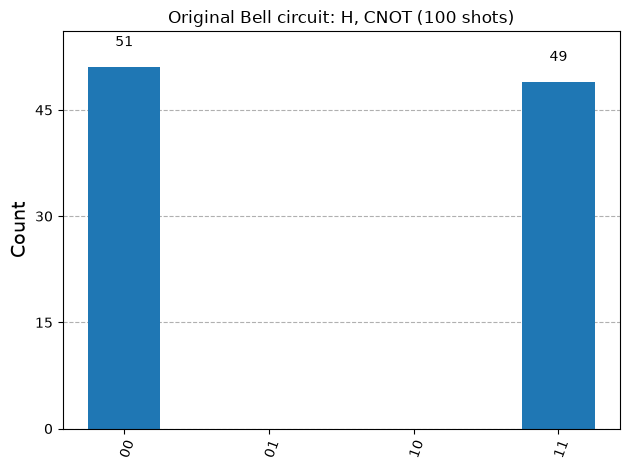

In [6]:
display(plot_histogram(counts_orig, title='Original Bell circuit: H, CNOT (100 shots)'))

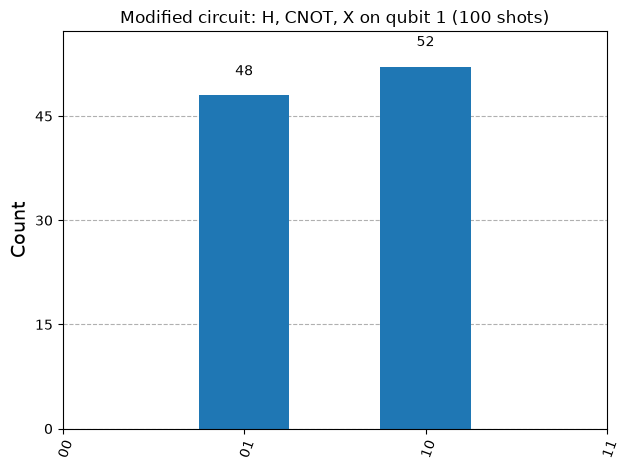

In [7]:
display(plot_histogram(counts_mod, title='Modified circuit: H, CNOT, X on qubit 1 (100 shots)'))

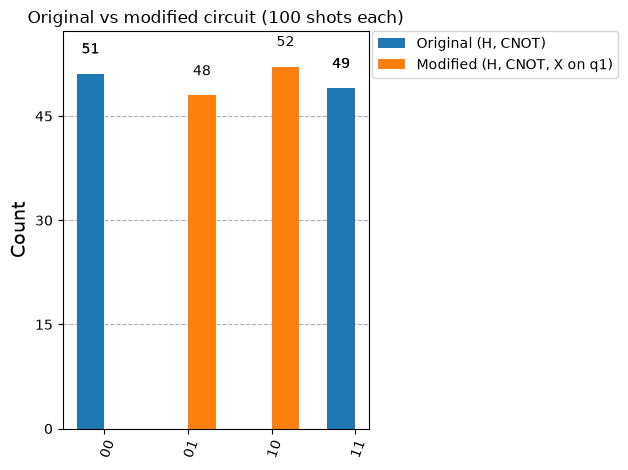

In [8]:
# Side-by-side comparison of the two circuits
display(plot_histogram(
    [counts_orig, counts_mod],
    legend=['Original (H, CNOT)', 'Modified (H, CNOT, X on q1)'],
    title='Original vs modified circuit (100 shots each)',
))

## Part 5: Compare predictions with actual results

In [9]:
def within_noise(count, p, shots=SHOTS, k=4):
    """True if a count is within k standard deviations of the expected value shots*p."""
    sd = sqrt(shots * p * (1 - p))
    return abs(count - shots * p) <= k * sd + 1


for name, pred, counts in [('Original', pred_orig, counts_orig), ('Modified', pred_mod, counts_mod)]:
    print(f'{name} circuit')
    print(f"  {'Outcome':<9}{'Predicted':<12}{'Actual (of 100)':<18}Match?")
    for s in STATES:
        expected = pred[s] * SHOTS
        print(f"  {s:<9}{expected:<12.0f}{counts[s]:<18}{'YES' if within_noise(counts[s], pred[s]) else 'NO'}")
    same = counts['00'] + counts['11']
    diff = counts['01'] + counts['10']
    print(f'  Qubits agree (00 or 11): {same}   Qubits differ (01 or 10): {diff}\n')

Original circuit
  Outcome  Predicted   Actual (of 100)   Match?
  00       50          51                YES
  01       0           0                 YES
  10       0           0                 YES
  11       50          49                YES
  Qubits agree (00 or 11): 100   Qubits differ (01 or 10): 0

Modified circuit
  Outcome  Predicted   Actual (of 100)   Match?
  00       0           0                 YES
  01       50          48                YES
  10       50          52                YES
  11       0           0                 YES
  Qubits agree (00 or 11): 0   Qubits differ (01 or 10): 100



## Optional extra: a gate that does NOT change the correlation

Adding a **Z gate on qubit 1** (instead of X) changes the state to (|00> - |11>)/sqrt(2). Only the sign (phase) changes, not the probabilities, so a Z-modified circuit still gives only `00` and `11`. This shows that to change the measured correlation, a gate must change which basis states are populated (as X does), not just their phase.

     ┌───┐          ┌─┐   
q_0: ┤ H ├──■───────┤M├───
     └───┘┌─┴─┐┌───┐└╥┘┌─┐
q_1: ─────┤ X ├┤ Z ├─╫─┤M├
          └───┘└───┘ ║ └╥┘
c: 2/════════════════╩══╩═
                     0  1 

Bell + Z results: {'00': 45, '11': 55}


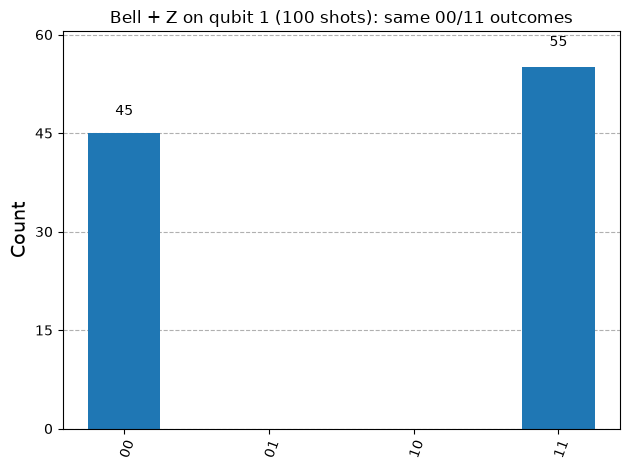

In [10]:
qc_z = QuantumCircuit(2, 2, name='Bell + Z')
qc_z.h(0)
qc_z.cx(0, 1)
qc_z.z(1)
qc_z.measure([0, 1], [0, 1])
print(qc_z.draw('text'))

counts_z = run_circuit(qc_z)
print('\nBell + Z results:', nonzero(counts_z))
display(plot_histogram(counts_z, title='Bell + Z on qubit 1 (100 shots): same 00/11 outcomes'))

## Short explanation of the observed change

- **Original circuit (H, CNOT):** the Hadamard puts qubit 0 in superposition and the CNOT entangles it with qubit 1, giving the Bell state (|00> + |11>)/sqrt(2). Each measurement gives `00` or `11` at random (about 50/50), but the two qubits **always agree**. `01` and `10` never occur.
- **Modified circuit (H, CNOT, X on qubit 1):** the X gate flips qubit 1, changing the state to (|01> + |10>)/sqrt(2). Now only `01` and `10` occur (about 50/50) and the qubits **always disagree**. `00` and `11` disappear.
- **Conclusion:** the entanglement is still there; each qubit on its own is still random (50% 0, 50% 1). What changed is the *type* of correlation, from perfectly correlated (same value) to perfectly anti-correlated (opposite values), using just one extra gate.
- **Prediction check:** the predictions held. The original gave only `00`/`11`, the modified gave only `01`/`10`, and the split between the two allowed outcomes is close to 50/50, with small differences from run to run because of random shot noise.